## Problema y objetivos

La empresa quiere identificar el género de una canción a partir de sus características de audio. La variable `id_genero` no es una etiqueta de sí o no, ni un valor numérico a estimar: toma 10 valores distintos y cada canción pertenece a una sola clase. El problema es de **clasificación supervisada multiclase**.

En este notebook el objetivo es entrenar una LSTM que clasifique cada fragmento de 3 segundos de `df_cancion_3s`. Cada fragmento entra como una secuencia en la que cada característica de audio es un paso, y la red le asigna una de esas 10 clases. El modelo se ajusta solo con los fragmentos de las canciones de entrenamiento; una parte de esas canciones se reserva para validación y el conjunto de test se deja para la evaluación. El resultado se mide con accuracy y F1 macro, para ver el acierto global y el rendimiento medio entre géneros.

## Selección de métricas y umbral

**Accuracy.** Hay 10 géneros y el mismo número de canciones en cada clase. Con ese reparto equilibrado, el porcentaje de aciertos resume el rendimiento global sin que una clase más frecuente lo distorsione.

**F1 macro.** Se calcula el F1 de cada género y se promedia dando el mismo peso a las 10 clases. Así, un género fácil de clasificar no compensa a otro que el modelo confunde. El F1 por clase del informe de clasificación muestra cuáles son esos géneros.

**Umbral de decisión.** El modelo devuelve una probabilidad para cada una de las 10 clases. La clase asignada es la de probabilidad más alta. No se exige una probabilidad mínima para aceptar la predicción: si la clase ganadora tiene, por ejemplo, 0,2 y el resto queda por debajo, esa clase se predice igualmente.

In [1]:
import pandas as pd
import numpy as np
import random
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [2]:
from pathlib import Path

def carpeta_proyecto(nombre, marca):
    """Localiza los CSV en Jupyter, Visual Studio Code y Colab."""
    from pathlib import Path
    import json

    saltar = {
        ".config", "sample_data", "drive", ".git", "__pycache__",
        "node_modules", ".ipynb_checkpoints", "site-packages",
    }

    def directorio_notebook():
        try:
            return Path(__vsc_ipynb_file__).resolve().parent
        except NameError:
            pass
        try:
            from urllib.request import urlopen
            try:
                from ipykernel.connect import get_connection_file
            except ImportError:
                from ipykernel import get_connection_file
            conexion = Path(get_connection_file())
            kernel_id = conexion.name.replace("kernel-", "").replace(".json", "")
            servidores = list(conexion.parent.glob("jpserver-*.json"))[:3]
            for servidor in servidores:
                try:
                    info = json.loads(servidor.read_text(encoding="utf-8"))
                except (OSError, json.JSONDecodeError):
                    continue
                url = str(info.get("url", "")).rstrip("/")
                raiz = info.get("root_dir")
                if not url or not raiz:
                    continue
                api = url + "/api/sessions"
                token = info.get("token") or ""
                if token:
                    api += "?token=" + token
                try:
                    with urlopen(api, timeout=0.8) as respuesta:
                        sesiones = json.loads(respuesta.read().decode())
                except Exception:
                    continue
                for sesion in sesiones:
                    kid = (sesion.get("kernel") or {}).get("id")
                    if kid != kernel_id:
                        continue
                    cuaderno = sesion.get("notebook") or {}
                    relativo = cuaderno.get("path") or sesion.get("path")
                    if relativo:
                        return (Path(raiz) / relativo).resolve().parent
        except Exception:
            pass
        return None

    bases = []
    notebook = directorio_notebook()
    if notebook is not None:
        bases.append(notebook)
    bases.append(Path.cwd().resolve())
    content = Path("/content")
    if content.is_dir():
        bases.append(content)
        drive = content / "drive" / "MyDrive"
        if drive.is_dir():
            bases.append(drive)

    nombradas = []
    sueltas = []
    vistos = set()

    def considerar(directorio, aceptar_suelto):
        if directorio in vistos:
            return
        vistos.add(directorio)
        try:
            carpeta = directorio / nombre
            if (carpeta / marca).is_file():
                nombradas.append(carpeta)
                return
            if directorio.name == nombre and (directorio / marca).is_file():
                nombradas.append(directorio)
                return
            if aceptar_suelto and (directorio / marca).is_file():
                sueltas.append(directorio)
        except OSError:
            return

    def hijos(directorio, profundidad, limite):
        if profundidad < 0 or limite[0] <= 0 or not directorio.is_dir():
            return
        try:
            entradas = list(directorio.iterdir())
        except OSError:
            return
        for hijo in entradas:
            if not hijo.is_dir() or hijo.name.startswith(".") or hijo.name in saltar:
                continue
            limite[0] -= 1
            considerar(hijo, False)
            if nombradas or limite[0] <= 0:
                return
            hijos(hijo, profundidad - 1, limite)
            if nombradas or limite[0] <= 0:
                return

    for base in bases:
        considerar(base, True)
        if nombradas:
            break
        for padre in list(base.parents)[:6]:
            considerar(padre, False)
            if nombradas:
                break
        if nombradas:
            break
        profundidad = 3 if base.name in {"content", "MyDrive"} else 2
        hijos(base, profundidad, [400])
        if nombradas:
            break

    if nombradas:
        return nombradas[0]
    if sueltas:
        return sueltas[0]
    raise FileNotFoundError(
        "No se encuentra " + marca + ". "
        "Tiene que existir la carpeta '" + nombre + "' en el proyecto, "
        "o el archivo en el directorio de trabajo. En Colab puede estar junto a sample_data."
    )


def carpeta_datos():
    """Carpeta datos preprocesados, en Jupyter, Visual Studio Code o Colab."""
    return carpeta_proyecto("datos preprocesados", "ids_train.csv")

DATOS = carpeta_datos()
print("Datos:", DATOS)

#Cargamos los datos, y la seleccion que hemos decidido para train y test
df = pd.read_csv(DATOS / "df_cancion_3s.csv")
ids_train = pd.read_csv(DATOS / "ids_train.csv")['id_cancion']
ids_test = pd.read_csv(DATOS / "ids_test.csv")['id_cancion']

## Preprocesamiento

El conjunto de test queda fuera del ajuste. De las canciones de entrenamiento se aparta un 20 %, estratificado por `id_genero`, para validación. Los fragmentos de una misma canción no se reparten entre entrenamiento y validación. El `StandardScaler` se ajusta solo con las canciones que sí entran al entrenamiento.

In [3]:
from pathlib import Path

def carpeta_proyecto(nombre, marca):
    """Localiza los CSV en Jupyter, Visual Studio Code y Colab."""
    from pathlib import Path
    import json

    saltar = {
        ".config", "sample_data", "drive", ".git", "__pycache__",
        "node_modules", ".ipynb_checkpoints", "site-packages",
    }

    def directorio_notebook():
        try:
            return Path(__vsc_ipynb_file__).resolve().parent
        except NameError:
            pass
        try:
            from urllib.request import urlopen
            try:
                from ipykernel.connect import get_connection_file
            except ImportError:
                from ipykernel import get_connection_file
            conexion = Path(get_connection_file())
            kernel_id = conexion.name.replace("kernel-", "").replace(".json", "")
            servidores = list(conexion.parent.glob("jpserver-*.json"))[:3]
            for servidor in servidores:
                try:
                    info = json.loads(servidor.read_text(encoding="utf-8"))
                except (OSError, json.JSONDecodeError):
                    continue
                url = str(info.get("url", "")).rstrip("/")
                raiz = info.get("root_dir")
                if not url or not raiz:
                    continue
                api = url + "/api/sessions"
                token = info.get("token") or ""
                if token:
                    api += "?token=" + token
                try:
                    with urlopen(api, timeout=0.8) as respuesta:
                        sesiones = json.loads(respuesta.read().decode())
                except Exception:
                    continue
                for sesion in sesiones:
                    kid = (sesion.get("kernel") or {}).get("id")
                    if kid != kernel_id:
                        continue
                    cuaderno = sesion.get("notebook") or {}
                    relativo = cuaderno.get("path") or sesion.get("path")
                    if relativo:
                        return (Path(raiz) / relativo).resolve().parent
        except Exception:
            pass
        return None

    bases = []
    notebook = directorio_notebook()
    if notebook is not None:
        bases.append(notebook)
    bases.append(Path.cwd().resolve())
    content = Path("/content")
    if content.is_dir():
        bases.append(content)
        drive = content / "drive" / "MyDrive"
        if drive.is_dir():
            bases.append(drive)

    nombradas = []
    sueltas = []
    vistos = set()

    def considerar(directorio, aceptar_suelto):
        if directorio in vistos:
            return
        vistos.add(directorio)
        try:
            carpeta = directorio / nombre
            if (carpeta / marca).is_file():
                nombradas.append(carpeta)
                return
            if directorio.name == nombre and (directorio / marca).is_file():
                nombradas.append(directorio)
                return
            if aceptar_suelto and (directorio / marca).is_file():
                sueltas.append(directorio)
        except OSError:
            return

    def hijos(directorio, profundidad, limite):
        if profundidad < 0 or limite[0] <= 0 or not directorio.is_dir():
            return
        try:
            entradas = list(directorio.iterdir())
        except OSError:
            return
        for hijo in entradas:
            if not hijo.is_dir() or hijo.name.startswith(".") or hijo.name in saltar:
                continue
            limite[0] -= 1
            considerar(hijo, False)
            if nombradas or limite[0] <= 0:
                return
            hijos(hijo, profundidad - 1, limite)
            if nombradas or limite[0] <= 0:
                return

    for base in bases:
        considerar(base, True)
        if nombradas:
            break
        for padre in list(base.parents)[:6]:
            considerar(padre, False)
            if nombradas:
                break
        if nombradas:
            break
        profundidad = 3 if base.name in {"content", "MyDrive"} else 2
        hijos(base, profundidad, [400])
        if nombradas:
            break

    if nombradas:
        return nombradas[0]
    if sueltas:
        return sueltas[0]
    raise FileNotFoundError(
        "No se encuentra " + marca + ". "
        "Tiene que existir la carpeta '" + nombre + "' en el proyecto, "
        "o el archivo en el directorio de trabajo. En Colab puede estar junto a sample_data."
    )


def carpeta_datos():
    """Carpeta datos preprocesados, en Jupyter, Visual Studio Code o Colab."""
    return carpeta_proyecto("datos preprocesados", "ids_train.csv")

DATOS = carpeta_datos()
print("Datos:", DATOS)

# Cargar IDs de entrenamiento y prueba
train_ids = pd.read_csv(DATOS / "ids_train.csv")
test_ids = pd.read_csv(DATOS / "ids_test.csv")

# Filtrar el DataFrame principal para crear los conjuntos de entrenamiento y prueba
df_train = df[df["id_cancion"].isin(train_ids["id_cancion"])].copy()
df_test = df[df["id_cancion"].isin(test_ids["id_cancion"])].copy()

# Validación: 20 % de las canciones de train. El test no entra aquí.
genero_cancion = df_train.groupby("id_cancion")["id_genero"].first()
id_fit, id_val = train_test_split(
    genero_cancion.index,
    test_size=0.2,
    random_state=42,
    stratify=genero_cancion.values,
)
df_fit = df_train[df_train["id_cancion"].isin(id_fit)].copy()
df_val = df_train[df_train["id_cancion"].isin(id_val)].copy()

# Columnas numéricas del propio dataframe. Fuera quedan los identificadores,
# la etiqueta y duracion (tiene nulos y la LSTM no los admite).
columnas_fuera = [
    "id_cancion",
    "id_genero",
    "id_disco",
    "id_autor",
    "id_discografica",
    "duracion",
]
X_train_raw = df_fit.select_dtypes(include="number").drop(columns=columnas_fuera)
y_train_raw = df_fit["id_genero"]

X_val_raw = df_val.select_dtypes(include="number").drop(columns=columnas_fuera)
y_val_raw = df_val["id_genero"]

X_test_raw = df_test.select_dtypes(include="number").drop(columns=columnas_fuera)
y_test_raw = df_test["id_genero"]

# Escalar los datos (fit solo con el entrenamiento, sin validación ni test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)
X_test_scaled = scaler.transform(X_test_raw)

print("X_train:", X_train_scaled.shape, "X_val:", X_val_scaled.shape, "X_test:", X_test_scaled.shape)


X_train: (6392, 59) X_val: (1598, 59) X_test: (2000, 59)


## Preparación de datos para la LSTM

Cada fragmento pasa a ser una secuencia: las características de audio son los pasos temporales y en cada paso hay un solo valor. Así puede entrar en la LSTM.

In [4]:
# Codificar etiquetas (los ids de genero no son 0..n-1 y pueden tener huecos)
label_encoder = LabelEncoder()
label_encoder.fit(y_train_raw)  # solo clases vistas en entrenamiento

y_train = label_encoder.transform(y_train_raw)
y_val = label_encoder.transform(y_val_raw)
y_test = label_encoder.transform(y_test_raw)

n_classes = len(label_encoder.classes_)
print("Clases (id_genero):", label_encoder.classes_)
print("Numero de clases:", n_classes)

# Reformatear a (muestras, timesteps, features_por_paso) para la LSTM
# Aqui cada caracteristica se trata como un paso temporal con 1 valor
X_train = X_train_scaled.reshape((X_train_scaled.shape[0], X_train_scaled.shape[1], 1))
X_val = X_val_scaled.reshape((X_val_scaled.shape[0], X_val_scaled.shape[1], 1))
X_test = X_test_scaled.reshape((X_test_scaled.shape[0], X_test_scaled.shape[1], 1))

print("X_train shape (LSTM):", X_train.shape)
print("X_val shape (LSTM):", X_val.shape)
print("X_test shape (LSTM):", X_test.shape)


Clases (id_genero): [ 1  2  3  4  5  6  7  8  9 10]
Numero de clases: 10
X_train shape (LSTM): (6392, 59, 1)
X_val shape (LSTM): (1598, 59, 1)
X_test shape (LSTM): (2000, 59, 1)


## Definición y entrenamiento del modelo LSTM

In [5]:
n_timesteps = X_train.shape[1]
n_features = X_train.shape[2]

modelo = Sequential([
    LSTM(128, return_sequences=True, input_shape=(n_timesteps, n_features)), # Aumentar unidades LSTM
    Dropout(0.3),
    LSTM(64), # Aumentar unidades LSTM
    Dropout(0.3),
    Dense(64, activation="relu"), # Aumentar unidades Dense
    Dense(n_classes, activation="softmax")
])

modelo.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

modelo.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 59, 128)        │        66,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 59, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 120,778 (471.79 KB)

 Trainable params: 120,778 (471.79 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

historia = modelo.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100, # Aumentar el número de épocas
    batch_size=32, # Ajustar el tamaño del batch
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 35s 155ms/step - accuracy: 0.2550 - loss: 1.9344 - val_accuracy: 0.3260 - val_loss: 1.7943
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 22s 110ms/step - accuracy: 0.3561 - loss: 1.7289 - val_accuracy: 0.3692 - val_loss: 1.6658
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 23s 114ms/step - accuracy: 0.3894 - loss: 1.6391 - val_accuracy: 0.3974 - val_loss: 1.6473
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 42s 118ms/step - accuracy: 0.4028 - loss: 1.6116 - val_accuracy: 0.4074 - val_loss: 1.6176
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 40s 111ms/step - accuracy: 0.4207 - loss: 1.5746 - val_accuracy: 0.4111 - val_loss: 1.6008
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 22s 110ms/step - accuracy: 0.4399 - loss: 1.5330 - val_accuracy: 0.4136 - val_loss: 1.6081
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - accuracy: 0.4681 - loss: 1.4719 - val_accuracy: 0.4549 - val_loss: 1.4978
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 22s 110ms/step - accuracy: 0.4916 -

## Curvas de entrenamiento

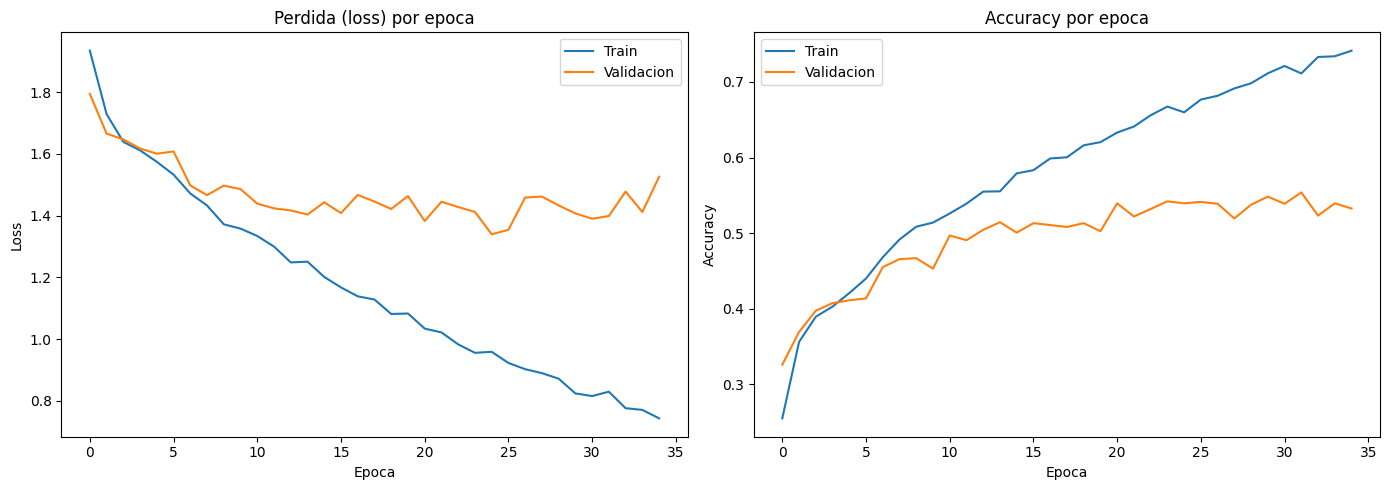

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(historia.history["loss"], label="Train")
axes[0].plot(historia.history["val_loss"], label="Validacion")
axes[0].set_title("Perdida (loss) por epoca")
axes[0].set_xlabel("Epoca")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(historia.history["accuracy"], label="Train")
axes[1].plot(historia.history["val_accuracy"], label="Validacion")
axes[1].set_title("Accuracy por epoca")
axes[1].set_xlabel("Epoca")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

Aquí se generan dos **gráficos importantes** para entender cómo fue el entrenamiento:

*   **Gráfico de Pérdida (Loss)**: Muestra qué tan bien se está equivocando el modelo. Queremos que la línea de "Train" y "Validacion" baje lo más posible y se mantengan cerca.
*   **Gráfico de Precisión (Accuracy)**: Muestra qué tan a menudo el modelo acierta. Queremos que ambas líneas suban lo más posible y se mantengan cerca. Si la línea de entrenamiento sube mucho y la de validación se estanca o baja, es señal de que el modelo se está "aprendiendo de memoria" los datos de entrenamiento (sobreajuste).

La línea de validación es el 20 % de canciones apartado del entrenamiento. El conjunto de test no aparece en estas curvas: se usa solo en la evaluación final.

## Evaluacion

63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step


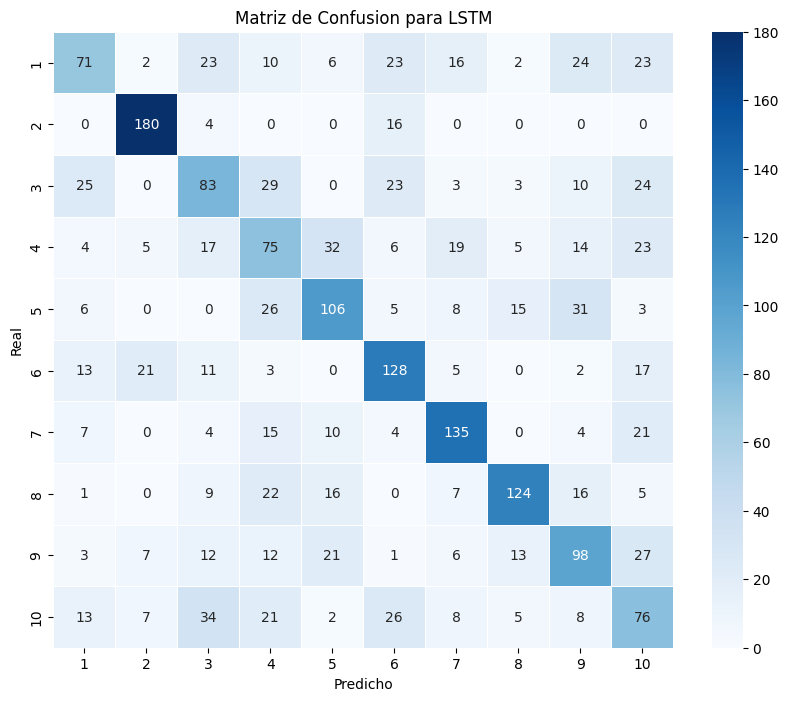

Accuracy (LSTM): 0.538

Reporte de Clasificacion (LSTM):
              precision    recall  f1-score   support

           1       0.50      0.35      0.41       200
           2       0.81      0.90      0.85       200
           3       0.42      0.41      0.42       200
           4       0.35      0.38      0.36       200
           5       0.55      0.53      0.54       200
           6       0.55      0.64      0.59       200
           7       0.65      0.68      0.66       200
           8       0.74      0.62      0.68       200
           9       0.47      0.49      0.48       200
          10       0.35      0.38      0.36       200

    accuracy                           0.54      2000
   macro avg       0.54      0.54      0.54      2000
weighted avg       0.54      0.54      0.54      2000



In [8]:
# Predicciones
y_pred_probs = modelo.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

# Volvemos a las etiquetas originales de genero para que el reporte sea legible
y_test_labels = label_encoder.inverse_transform(y_test)
y_pred_labels = label_encoder.inverse_transform(y_pred)

# Matriz de confusion
cm = confusion_matrix(y_test_labels, y_pred_labels, labels=label_encoder.classes_)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("Matriz de Confusion para LSTM")
plt.xlabel("Predicho")
plt.ylabel("Real")
plt.show()

# Evaluacion
print(f"Accuracy (LSTM): {accuracy_score(y_test_labels, y_pred_labels)}")
print("\nReporte de Clasificacion (LSTM):")
print(classification_report(y_test_labels, y_pred_labels))


**Conclusión**: El accuracy de entrenamiento sube de forma continua y en la época 35 ronda el 0,74, mientras el de validación, a partir de la época 14, se mueve entre 0,50 y 0,55 y deja de acompañar al entrenamiento. Esa separación indica sobreajuste. EarlyStopping corta en la época 35 y recupera los pesos de la época 25, la de menor pérdida de validación (1,34), con un accuracy de validación de 0,54.

**Conclusión final**: La LSTM clasifica cada fragmento de 3 segundos. Sobre los 2000 fragmentos de prueba alcanza un 53,8 % de accuracy y un F1 macro de 0,54. El rendimiento es desigual entre géneros: en el classification report destaca la clase 2 (F1 0,85) y, por detrás, las clases 8 y 7 (F1 0,68 y 0,66). Las clases 4 y 10 quedan en 0,36, y las clases 1 y 3 en 0,41 y 0,42. El accuracy de prueba coincide con el de la validación del modelo restaurado (0,54).